#this SHIT to be removed

In [1]:
import pandas as pd
import yaml 

# Here, each → represents a tab. Without sep="\t", read_csv() expects commas and would read the rows incorrectly.
df_2023 = pd.read_csv("dataset/Dataminers 2023.tsv", sep='\t')
df_2024 = pd.read_json("dataset/Dataminers 2024.json")
#  parser="etree" tells pandas which XML-reading engine to use. etree uses Python’s built-in XML parser, so you don’t need the optional lxml library that pandas uses by default.
df_2025 = pd.read_xml("dataset/Dataminers_2025.xml", parser='etree')


with open("dataset/Dataminers 2026.yaml", encoding="utf-8") as file:
      df_2026 = pd.DataFrame(yaml.safe_load(file))




In [2]:
#just checking what columns each table has
for df in [df_2023, df_2024, df_2025, df_2026]:
    print(df.columns.tolist())

['Timestamp', 'Your mean shoe size (In European Continental system)  ', 'Which programme are you studying?', 'Your height (in International inches)', 'Why are you taking this course?', 'How many letters are there in the word "Seattle"?']
['Timestamp', 'Enter Your Password', 'Your mean shoe size (In the European Continental system)', 'Which program are you studying?', 'Your height (in International inches)', 'Why are you taking this course?', 'How many letters are there in the word "Seattle"?']
['Timestamp', 'Enter_Your_Password', 'Your_mean_shoe_size__In_the_European_Continental_system_', 'Which_program_are_you_studying_', 'Your_height__in_International_inches_', 'Why_are_you_taking_this_course_', 'How_many_letters_are_there_in_the_word__Seattle__']
['Timestamp', 'Enter Your Password', 'Your mean shoe size (In the European Continental system)', 'Which program are you studying?', 'Your height (in International inches)', 'Why are you taking this course?', 'How many letters are there in t

In [3]:

tables = [df_2023, df_2024, df_2025, df_2026]
clean_tables = []

for df in tables:
      # Remove passwords and create a separate table.
      cleaned = df.drop(
          columns=["Enter Your Password", "Enter_Your_Password"],
          errors="ignore", #If the column doesn't exist, don't give me an error. Just continue.
      ).copy()

      # In your files, the six remaining questions have the same order.
      #Replace the current column names with these new names
      cleaned.columns = [
          "timestamp",
          "shoe_size",
          "programme",
          "height",
          "course_reason",
          "seattle_letters",
      ]

      clean_tables.append(cleaned)

  # Combine rows now that the column names match.
  #So concat is basically stacking the tables on top of each other.
  #Ignore the old row numbers and create new row numbers: 0, 1, 2, 3, 4, 5...
students_df = pd.concat(clean_tables, ignore_index=True)

print(students_df.shape)
students_df

(223, 6)


,timestamp,shoe_size,programme,height,course_reason,seattle_letters
0,26/08/2020 08:32:49,44.0,"MSc Software Design, ITU",75.59,It'll give me business skills,NaN
1,26/08/2020 08:33:16,38.0,"MSc Software Design, ITU",167.0,"It is the most exciting, This was mandatory fo...",NaN
2,26/08/2020 08:33:22,44.0,"MSc Software Design, ITU",192.0,This was mandatory for me,NaN
3,26/08/2020 08:33:24,38.0,"MSc Software Design, ITU",66.0,"It is the most exciting, It'll give me busines...",NaN
4,26/08/2020 08:33:25,44.0,"MSc Software Design, ITU",184.0,It'll give me business skills,NaN
...,...,...,...,...,...,...
218,2026/09/17 8:07:40 AM PDT,44,"MSc Software Design, ITU",1.85,It is the most exciting;It'll give me commerci...,7
219,2026/09/17 10:45:36 AM PDT,39,"MSc Software Design, ITU",65,it seemed interesting,7
220,2026/09/17 12:33:23 PM PDT,42.5,"MSc Software Design, ITU","6,1",The other courses were even less attractive,7
221,2026/09/20 5:32:57 AM PDT,43,"MSc Software Design, ITU",69.3,It is the most exciting;It'll give me commerci...,7


In [4]:
print(students_df.columns.tolist())
print("Rows and columns:", students_df.shape)

['timestamp', 'shoe_size', 'programme', 'height', 'course_reason', 'seattle_letters']
Rows and columns: (223, 6)


In [5]:
# Keep only height and shoe size to explore their relationship
# and test how accurately height can predict shoe size.

height_shoe_df = students_df[["height", "shoe_size"]].copy() # when we use copy it wont affect students_df later if we chnange
print(height_shoe_df.isna().sum())
height_shoe_df.head()



height       0
shoe_size    0
dtype: int64


,height,shoe_size
0,75.59,44.0
1,167.0,38.0
2,192.0,44.0
3,66.0,38.0
4,184.0,44.0


Analysisng heigh data

In [6]:
# Inspect all height responses before deciding how to convert them
#Counts how often each distinct height appears**, including missing values.
#value_counts()` counts occurrences of each value.
#dropna=False` means **include missing values (`NaN`) in the counts**. By default, they’re excluded.
print(height_shoe_df["height"].value_counts(dropna=False).to_string())


height
68.0           7
72.0           5
71             5
70.0           4
65             4
72             4
70             4
175            4
66.0           3
64.0           3
69.0           3
73.0           3
75             3
68.11          3
73             3
74.8           3
65.0           2
74.0           2
70.07          2
71.0           2
63.0           2
70.8           2
180            2
193            2
68.8976        2
66             2
66.14          2
70,87          2
67             2
68             2
72.44          2
62.99          2
74             2
5'10           2
64             2
68.9           2
75.59          1
167.0          1
192.0          1
184.0          1
71.65          1
70.07874       1
5.6            1
75.984         1
63.4           1
71.3           1
187.0          1
174.0          1
6.1            1
73.23          1
178.0          1
63.78          1
64.566929      1
67.7           1
68.9           1
71.2           1
70.5           1
55.0           1
70.9   

In [7]:
# Remove the response that does not describe a height, analysisng data i found 1 ton as an answer so removed it manually
height_shoe_df = height_shoe_df[height_shoe_df["height"] != "1 ton"]
height_shoe_df

,height,shoe_size
0,75.59,44.0
1,167.0,38.0
2,192.0,44.0
3,66.0,38.0
4,184.0,44.0
...,...,...
218,1.85,44
219,65,39
220,"6,1",42.5
221,69.3,43


Convert explicit units and feet/inches notation to centimetres. For ambiguous shorthand, assume `5.6` means 5 feet 6 inches and `6,1` means 6 feet 1 inch, rather than decimal feet. These interpretations are assumptions. `70'1` remains unresolved and is excluded from `analysis_df`; `1 ton` is removed earlier. Original height responses are retained for reference.


In [8]:
# Recover labelled heights and feet/inches responses.
# Assumption: 5.6 means 5 feet 6 inches; commas use the same convention.
import re
import numpy as np
#write in the report about that shit!!!!!
def height_to_cm(value):
    text = str(value).strip().lower().replace(",", ".")

    # Explicit cm
    if "cm" in text:
        return float(re.findall(r"[\d.]+", text)[0])

    # Explicit inches
    if "inch" in text:
        return float(re.findall(r"[\d.]+", text)[0]) * 2.54

    # Feet/inches: 5'10", 6''2, etc.
    match = re.fullmatch(r"(\d+)\s*'+\s*(\d+)\s*[\"']*", text)
    if match:
        feet, inches = map(int, match.groups())
        if 4 <= feet <= 7 and 0 <= inches < 12:
            return (feet * 12 + inches) * 2.54
        return np.nan  # 70'1 is unclear, not 70 feet tall.

    # Assumption: decimal-looking shorthand gives feet and inches.
    match = re.fullmatch(r"([4-7])\.(\d{1,2})", text)
    if match:
        feet, inches = map(int, match.groups())
        if 0 <= inches < 12:
            return (feet * 12 + inches) * 2.54
        return np.nan

    try:
        h = float(text)
        #write in the report about that shit!!!!!
        if 1.3 <= h <= 2.3:       # metres
            return h * 100

        if 50 <= h <= 90:         # inches
            return h * 2.54

        if 130 <= h <= 230:       # centimetres
            return h

    except ValueError:
        pass

    return np.nan

height_shoe_df["height_cm"] = height_shoe_df["height"].apply(height_to_cm)

In [9]:
# Create the analysis table after recovering the clear height formats.
# Keep height_shoe_df so excluded responses can still be reviewed.
#reoved unresolved rows
# Show rows missing either required value
unresolved = height_shoe_df[["height_cm", "shoe_size"]].isna().any(axis=1)
print("Unresolved rows:")
display(height_shoe_df.loc[unresolved])

analysis_df = height_shoe_df.dropna(
    subset=["height_cm", "shoe_size"]
).copy()

print(f"Rows excluded at this step: {unresolved.sum()}")
print(f"Rows kept for analysis: {len(analysis_df)}")
analysis_df.head()

Unresolved rows:


,height,shoe_size,height_cm
156,70'1,43,NaN


Rows excluded at this step: 1
Rows kept for analysis: 221


,height,shoe_size,height_cm
0,75.59,44.0,191.9986
1,167.0,38.0,167.0000
2,192.0,44.0,192.0000
3,66.0,38.0,167.6400
4,184.0,44.0,184.0000


Analysing shoes data

In [10]:
# Ensure shoe sizes are numeric; raise an error for unexpected text
analysis_df["shoe_size"] = pd.to_numeric(
    analysis_df["shoe_size"]
    .astype(str)
    .str.strip()
    .str.replace(r"(?i)^EU\s*", "", regex=True)
    .str.replace(",", ".", regex=False),
    errors="raise"
)



In [11]:
# Inspect potentially inconsistent shoe sizes without removing any rows.
print(analysis_df["shoe_size"].value_counts().sort_index())

shoe_size
6.0      1
7.5      1
9.0      2
36.0     4
37.0    15
37.5     1
38.0    23
38.5     3
39.0    30
39.5     1
40.0    14
40.5     1
41.0    11
41.5     3
42.0    22
42.5     5
43.0    23
43.5     3
44.0    25
44.5     2
45.0    17
46.0    14
Name: count, dtype: int64


In [12]:
# Exclude responses whose shoe-size system cannot be established.
# The question requested EU sizes; do not guess conversions from US/UK sizes.
unknown_units = analysis_df["shoe_size"].isin([6, 7.5, 9])

excluded_shoe_rows = analysis_df.loc[unknown_units].copy()
display(excluded_shoe_rows)
print(f"Excluded rows: {unknown_units.sum()}")

analysis_df = analysis_df.loc[~unknown_units].copy()


,height,shoe_size,height_cm
44,55.0,9.0,139.70
62,158.0,6.0,158.00
67,69.0,7.5,175.26
117,"5,9",9.0,175.26


Excluded rows: 4


Plotting

,height_cm,shoe_size
count,217.000000,217.000000
mean,176.466350,41.315668
std,9.567892,2.812939
min,150.000000,36.000000
25%,168.000000,39.000000
50%,177.800000,42.000000
75%,183.997600,44.000000
max,196.999860,46.000000


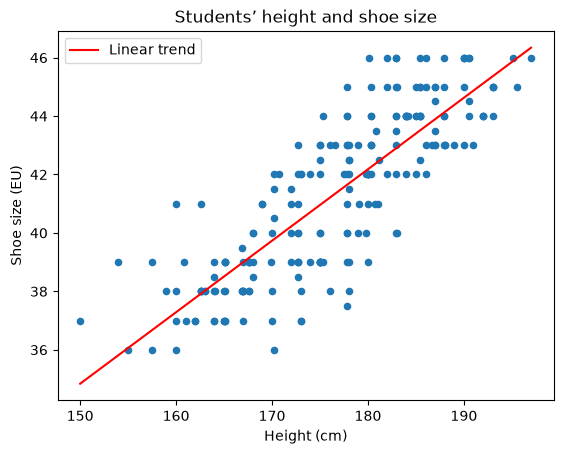

Pearson correlation: 0.832


In [13]:
import matplotlib.pyplot as plt
import numpy as np

display(analysis_df[["height_cm", "shoe_size"]].describe())

analysis_df.plot.scatter(x="height_cm", y="shoe_size")

# Fit and draw a straight trend line.
x = analysis_df["height_cm"]
y = analysis_df["shoe_size"]
slope, intercept = np.polyfit(x, y, 1)
line_x = np.array([x.min(), x.max()])

plt.plot(line_x, slope * line_x + intercept,
         color="red", label="Linear trend")

plt.xlabel("Height (cm)")
plt.ylabel("Shoe size (EU)")
plt.title("Students’ height and shoe size")
plt.legend()
plt.show()

correlation = x.corr(y)
print(f"Pearson correlation: {correlation:.3f}")

Training Models

In [14]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

# Input must be a table (double brackets); target is a single column.
X = analysis_df[["height_cm"]]
y = analysis_df["shoe_size"]

# Keep 20% of students aside for testing.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Learn the relationship using only the training data.
model = LinearRegression()
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[0.24]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['height_cm']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-0.7536
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


In [15]:
from sklearn.metrics import mean_absolute_error

predictions = model.predict(X_test)
#Is my linear regression actually better than making a stupid/simple guess?
baseline = [y_train.mean()] * len(y_test)


print("Regression MAE:", mean_absolute_error(y_test, predictions)) #1.11
print("Baseline MAE:", mean_absolute_error(y_test, baseline)) #2.64
#regression is making better prediction than simply guessing the avaerage shoe size

Regression MAE: 1.1117740334921
Baseline MAE: 2.6418155543878097


KNN regression predicts shoe size by averaging the training shoe sizes of students with the nearest heights. Five-fold cross-validation selects the number of neighbours using training data only. The test set is used for the final comparison, not for choosing this setting. Lower MAE is better.


In [16]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.model_selection import GridSearchCV, KFold

# Find a suitable number of neighbours using only training data.
knn_search = GridSearchCV(
    KNeighborsRegressor(),
    param_grid={"n_neighbors": [3, 5, 7, 9, 11, 15, 21]},# try all those values and figure out which one predicts best
    scoring="neg_mean_absolute_error", #This tells GridSearch how to decide which model is best.
    cv=KFold(n_splits=5, shuffle=True, random_state=42),
)
knn_search.fit(X_train, y_train)

# GridSearchCV refits the best model on the full training set.
knn_predictions = knn_search.predict(X_test)

print("Selected number of neighbours:", knn_search.best_params_["n_neighbors"])
print(f"KNN training CV MAE: {-knn_search.best_score_:.2f}")

# Compare all three methods on the same held-out test students.
comparison = pd.DataFrame({
    "Model": ["Mean baseline", "Linear regression", "KNN regression"],
    "Test MAE": [
        mean_absolute_error(y_test, baseline),
        mean_absolute_error(y_test, model.predict(X_test)),
        mean_absolute_error(y_test, knn_predictions),
    ],
})
display(comparison.round(3))


Selected number of neighbours: 21
KNN training CV MAE: 1.27


,Model,Test MAE
0,Mean baseline,2.642
1,Linear regression,1.112
2,KNN regression,1.065


**What is the relationship between students’ height and shoe size?**

> Height and shoe size showed a strong positive correlation (Pearson’s r = 0.832), suggesting that taller students generally have larger shoe sizes.
> 

**This does not mean the model is 83.2% accurate.** **0.832 describes how closely height and shoe size follow an upward straight-line pattern.** It doesn’t measure the percentage of correct predictions.

**How accurately can height predict shoe size?**

Linear regression predicted shoe size with an average absolute error of approximately 1.11 EU size units, reducing error by about 58% compared with the mean baseline. KNN performed slightly better, with an MAE of 1.07. Its improvement over linear regression was small—approximately 0.05 size units, and this single test split does not establish that KNN consistently performs better.